# Day 2 - Từ annotation YOLO đến detector YOLO26

Notebook này chạy **sau** khi nhãn 50 ảnh train đã qua cổng gold-set. Tập `eval` 10 ảnh không được dùng để train.

Quy trình chuẩn: bạn **fork repo đề bài**, gán nhãn, **commit và push** `dataset/labels/train/` lên repo của mình, rồi chỉ cần dán URL repo vào `REPO_URL` ở cell đầu tiên — Colab sẽ tự clone repo, train và đánh giá, không cần upload file.

Bài cá nhân. Hạn nộp: 11:59 trưa ngày hôm sau buổi lab (UTC+7); ca 09/11/2026 nộp trước 11:59 ngày 10/11/2026.

## Kiểm tra trước khi chạy

- Đã **fork repo đề bài**, gán nhãn và **commit + push** `dataset/labels/train/` lên repo của bạn.
- Ở cell tiếp theo, dán **URL repo của bạn** vào `REPO_URL` — notebook tự clone, không cần upload file.
- Không có `gold_train_labels/` trong repo.
- Chạy từ trên xuống dưới; giữ nguyên `data.yaml` và split eval.
- mAP đo model; F1/IoU ở script trước đó đo chất lượng nhãn con người.

In [1]:
%pip -q install -U ultralytics

from pathlib import Path
import json
import os
import shutil
import subprocess
import torch
import yaml
from ultralytics import YOLO

# ==================================================================
# Bước 1 (bắt buộc): dán URL repo fork của bạn vào REPO_URL
#
# Dòng chuẩn của bài:
#   1. Fork repo đề bài, đổi tên theo chuẩn nộp
#      (K5-L2-DAY02-HoVaTen-MSSV-ObjectDetection).
#   2. Gán nhãn 50 ảnh, commit và push dataset/labels/train/ lên repo của bạn.
#   3. Mở notebook này trong Colab, dán URL repo, chạy cell này:
#      notebook tự clone repo của bạn và train, không cần upload file.
#
# Ví dụ:
#   REPO_URL = 'https://github.com/your-username/K5-L2-DAY02-HoVanA-20241234-ObjectDetection'
# ==================================================================
REPO_URL = 'https://github.com/o1676733391/K5-L2B-DAY02-PhamVanNgocVinh-03262-ObjectDetection'
assert 'your-username' not in REPO_URL, (
    'Hãy dán URL repo fork của bạn (đã commit + push nhãn) vào REPO_URL.'
)

# Trên Colab clone về /content/Day2-Lab; chạy ngoài Colab thì dùng ./Day2-Lab.
LAB_ROOT = Path('/content/Day2-Lab') if Path('/content').is_dir() else Path('Day2-Lab')

if LAB_ROOT.exists():
    # Chạy lại cell trong cùng phiên Colab: khôi phục các file đã được sửa
    # (ví dụ data.yaml ở lần chạy trước) rồi kéo bản mới nhất từ GitHub.
    # Nếu thư mục không phải bản clone của repo, xóa /content/Day2-Lab rồi chạy lại.
    print('Đã có sẵn thư mục, pull nội dung mới nhất từ GitHub...')
    subprocess.run(['git', '-C', str(LAB_ROOT), 'checkout', '--', '.'], check=True)
    subprocess.run(['git', '-C', str(LAB_ROOT), 'pull', '--ff-only'], check=True)
else:
    print(f'Clone {REPO_URL} -> {LAB_ROOT}')
    env = {**os.environ, 'GIT_TERMINAL_PROMPT': '0'}
    try:
        subprocess.run(['git', 'clone', REPO_URL, str(LAB_ROOT)], check=True, env=env)
    except subprocess.CalledProcessError:
        # Repo private: clone bằng token tài khoản GitHub của bạn trong Colab.
        # Nếu chưa: menu Tools -> sign in to GitHub, rồi chạy lại cell này.
        from google.colab import auth
        token = auth.user_token('github')
        auth_url = REPO_URL.replace('https://github.com', f'https://{token}@github.com')
        subprocess.run(['git', 'clone', auth_url, str(LAB_ROOT)], check=True)

last_commit = subprocess.run(
    ['git', '-C', str(LAB_ROOT), 'log', '-1', '--oneline'],
    check=True, capture_output=True, text=True,
).stdout.strip()
print('commit mới nhất trong repo:', last_commit)

DATA_YAML = LAB_ROOT / 'data.yaml'
TRAIN_IMAGES = LAB_ROOT / 'dataset/images/train'
TRAIN_LABELS = LAB_ROOT / 'dataset/labels/train'
EVAL_IMAGES = LAB_ROOT / 'dataset/images/eval'
EVAL_LABELS = LAB_ROOT / 'dataset/labels/eval'
RUNS = LAB_ROOT / 'outputs/yolo26_runs'
DEVICE = 0 if torch.cuda.is_available() else 'cpu'

# Ultralytics resolves a relative `path:` in data.yaml against its own global
# datasets dir, not against data.yaml's own folder. Rewrite it to an absolute
# path so training works regardless of where the repo was cloned.
_data_cfg = yaml.safe_load(DATA_YAML.read_text(encoding='utf-8'))
_data_cfg['path'] = str((LAB_ROOT / 'dataset').resolve())
DATA_YAML.write_text(yaml.dump(_data_cfg, allow_unicode=True, sort_keys=False), encoding='utf-8')

print('LAB_ROOT:', LAB_ROOT.resolve())
print('device:', DEVICE)

Đã có sẵn thư mục, pull nội dung mới nhất từ GitHub...
commit mới nhất trong repo: ae75823  Modified label order
LAB_ROOT: /content/Day2-Lab
device: 0


In [ ]:
def image_stems(directory):
    return {p.stem for ext in ('*.jpg', '*.jpeg', '*.png') for p in directory.glob(ext)}

train_images = image_stems(TRAIN_IMAGES)
train_labels = {p.stem for p in TRAIN_LABELS.glob('*.txt')}
eval_images = image_stems(EVAL_IMAGES)
eval_labels = {p.stem for p in EVAL_LABELS.glob('*.txt')}
assert len(train_images) == 50, f' cần 50 train images, thấy {len(train_images)}'
assert train_images == train_labels, f'train images/labels lệch: {sorted(train_images ^ train_labels)[:5]}'
assert len(eval_images) == 10 and eval_images == eval_labels, 'eval phải đủ 10 ảnh và nhãn'
print(f'OK: {len(train_images)} train + {len(eval_images)} eval; eval không đi vào train.')

OK: 50 train + 10 eval; eval không đi vào train.


## Huấn luyện

Bài thực hành dùng checkpoint `yolo26n.pt`. Với 50 ảnh, dùng model nano và ít epoch để minh họa vòng lặp dữ liệu; thời gian/metric không dùng làm benchmark sản phẩm.

In [ ]:
model = YOLO('yolo26n.pt')
train_result = model.train(
    data=str(DATA_YAML),
    epochs=50,
    imgsz=640,
    batch=-1,
    device=DEVICE,
    project=str(RUNS),
    name='vehicle_annotation',
    exist_ok=True,
    seed=20260909,
    plots=True,
)
BEST = Path(model.trainer.best)
print('best checkpoint:', BEST)

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Day2-Lab/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=vehicle_annotation, nbs=64, nms=None, opset=None, optimize=F

## Đánh giá đúng tập eval

`data.yaml` trỏ `val` tới 10 ảnh eval đã có nhãn. Không đổi `val` sang train để làm đẹp mAP. Ghi lại mAP50, mAP50-95, precision và recall.

Tập `eval` cũng được dùng làm validation trong quá trình train và chọn `best.pt`, nên không phải test set độc lập.

In [ ]:
best_model = YOLO(str(BEST))
metrics = best_model.val(data=str(DATA_YAML), split='val', device=DEVICE, plots=True, project=str(RUNS), name='vehicle_eval', exist_ok=True)
summary = {
    'precision': float(metrics.box.mp),
    'recall': float(metrics.box.mr),
    'map50': float(metrics.box.map50),
    'map50_95': float(metrics.box.map),
    'eval_images': len(eval_images),
    'checkpoint': str(BEST),
}
metrics_path = LAB_ROOT / 'outputs/model_eval_metrics.json'
metrics_path.parent.mkdir(parents=True, exist_ok=True)
metrics_path.write_text(json.dumps(summary, indent=2) + '\n')
print(json.dumps(summary, indent=2))

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2113.8±331.3 MB/s, size: 76.6 KB)
val: Scanning /content/Day2-Lab/dataset/labels/eval.cache... 10 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10/10 4.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 10.2it/s 0.1s
                   all         10        113      0.407      0.234      0.274      0.202
                   car         10         94      0.836      0.652      0.741      0.525
                 truck          5          5      0.654        0.2      0.239      0.206
                   bus          2          2          0          0     0.0142    0.00467
                   van          6         12      0.136     0.0833      0.103     0.0741
Speed: 0.4ms preprocess, 1.6ms inference,

In [ ]:
# Kiểm tra trực quan một vài ảnh eval; đây là bước bắt buộc trong báo cáo.
prediction_dir = LAB_ROOT / 'outputs/eval_predictions'
results = best_model.predict(source=str(EVAL_IMAGES), conf=0.25, device=DEVICE, save=True, project=str(prediction_dir), name='visuals', exist_ok=True)
PRED_SAVE_DIR = Path(results[0].save_dir)
print('predictions saved to:', PRED_SAVE_DIR)
archive = shutil.make_archive(str(LAB_ROOT / 'outputs/day2_colab_outputs'), 'zip', LAB_ROOT / 'outputs')
print('Đã tạo:', archive)


image 1/10 /content/Day2-Lab/dataset/images/eval/drive_051.jpg: 640x640 8 cars, 1 van, 11.3ms
image 2/10 /content/Day2-Lab/dataset/images/eval/drive_052.jpg: 640x640 11 cars, 1 bus, 11.9ms
image 3/10 /content/Day2-Lab/dataset/images/eval/drive_053.jpg: 640x640 5 cars, 3 buss, 1 van, 12.0ms
image 4/10 /content/Day2-Lab/dataset/images/eval/drive_054.jpg: 640x640 5 cars, 1 van, 11.4ms
image 5/10 /content/Day2-Lab/dataset/images/eval/drive_055.jpg: 640x640 5 cars, 11.4ms
image 6/10 /content/Day2-Lab/dataset/images/eval/drive_056.jpg: 640x640 14 cars, 1 bus, 3 vans, 11.5ms
image 7/10 /content/Day2-Lab/dataset/images/eval/drive_057.jpg: 640x640 10 cars, 12.3ms
image 8/10 /content/Day2-Lab/dataset/images/eval/drive_058.jpg: 640x640 20 cars, 2 buss, 11.8ms
image 9/10 /content/Day2-Lab/dataset/images/eval/drive_059.jpg: 640x640 5 cars, 1 truck, 1 van, 11.8ms
image 10/10 /content/Day2-Lab/dataset/images/eval/drive_060.jpg: 640x640 9 cars, 1 bus, 1 van, 12.1ms
Speed: 1.1ms preprocess, 11.8ms inf

## Xem trực tiếp kết quả dự đoán

Hiển thị 10 ảnh eval kèm box dự đoán ngay trong notebook, không cần tải file `.zip` về mới xem được.

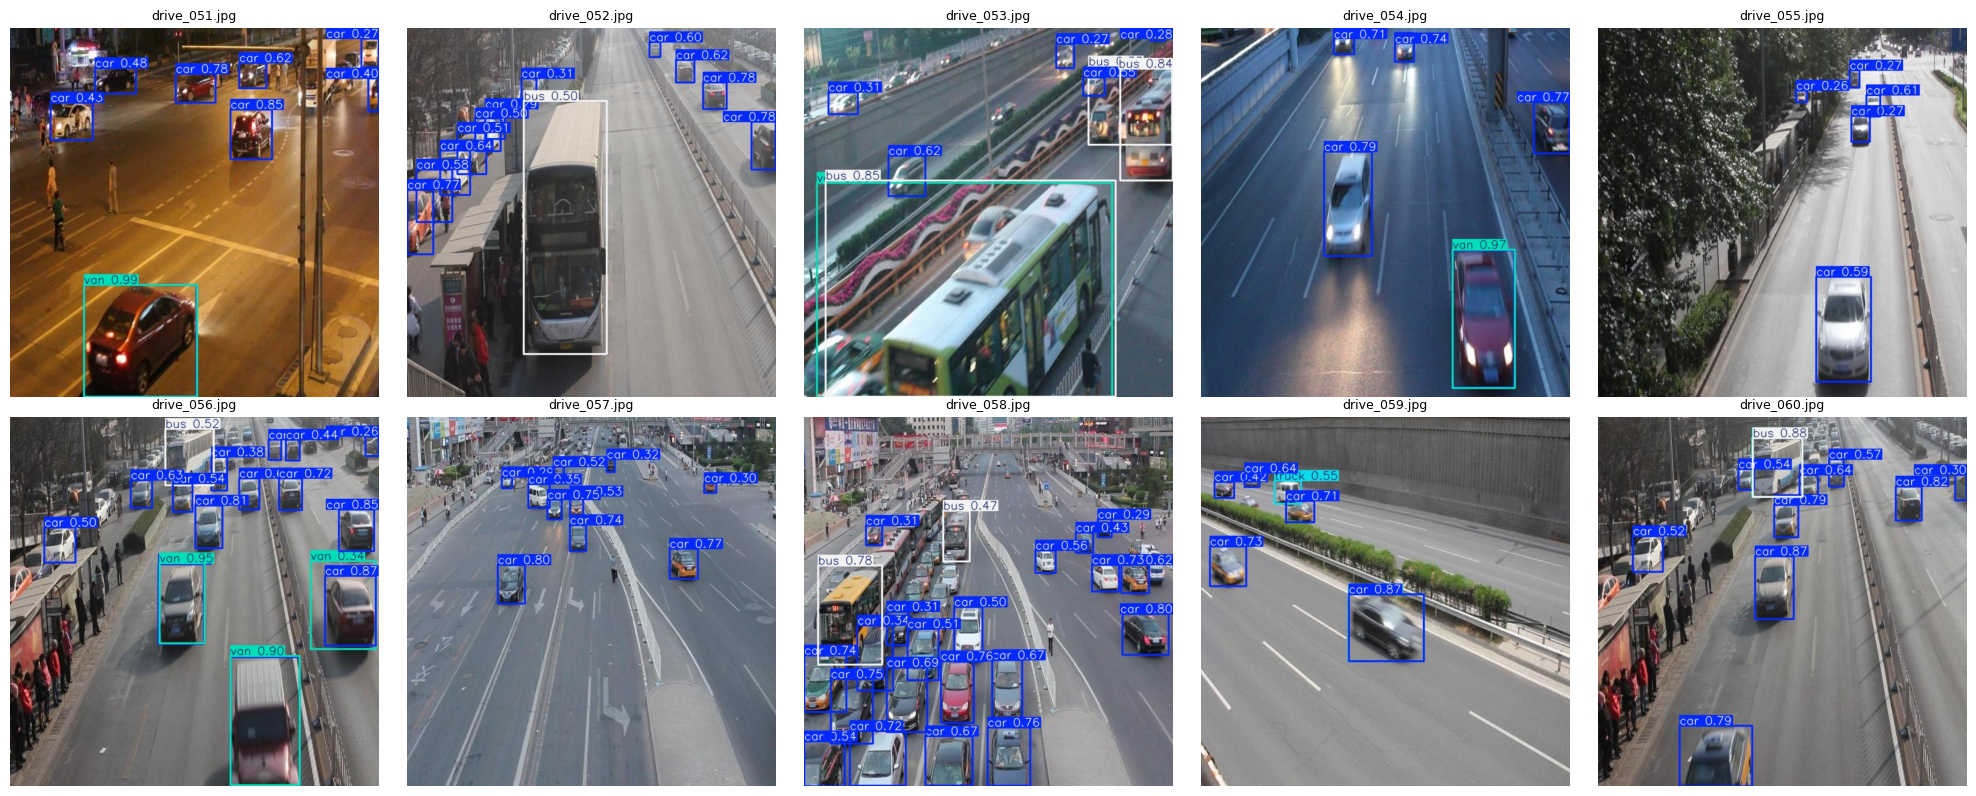

In [ ]:
import math
import matplotlib.pyplot as plt
from PIL import Image

pred_images = sorted(PRED_SAVE_DIR.glob('*.jpg'))
cols = 5
rows = math.ceil(len(pred_images) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
for ax, img_path in zip(axes.flat, pred_images):
    ax.imshow(Image.open(img_path))
    ax.set_title(img_path.name, fontsize=9)
    ax.axis('off')
for ax in axes.flat[len(pred_images):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

## Câu hỏi phân tích để nộp

1. Lớp nào có recall thấp nhất? Chỉ ra một ảnh eval minh họa.
2. Nếu mAP50 cao nhưng mAP50-95 thấp, box đang gặp vấn đề gì?
3. Có lỗi `truck`/`bus`/`van`/`car` nào liên quan tới guideline không?
4. Vì sao không dùng 10 ảnh eval để train dù chúng có nhãn?


Trích xuất `metrics.box.p`, `metrics.box.r`, `metrics.box.ap50`, `metrics.box.ap` của từng lớp để xác định lớp có recall thấp nhất và tìm ảnh eval minh họa.

           BẢNG CHỈ SỐ ĐÁNH GIÁ THEO TỪNG LỚP


,Class ID,Class Name,Precision,Recall,mAP50,mAP50-95
0,0,car,0.8362,0.6517,0.7406,0.5252
1,1,truck,0.6536,0.2000,0.2393,0.2057
2,2,bus,0.0000,0.0000,0.0142,0.0047
3,3,van,0.1363,0.0833,0.1026,0.0741



👉 LỚP CÓ RECALL THẤP NHẤT: 'bus' (Class 2) với Recall = 0.0000 (0.00%)
👉 Các ảnh eval chứa ground-truth 'bus': ['drive_051.jpg', 'drive_058.jpg']


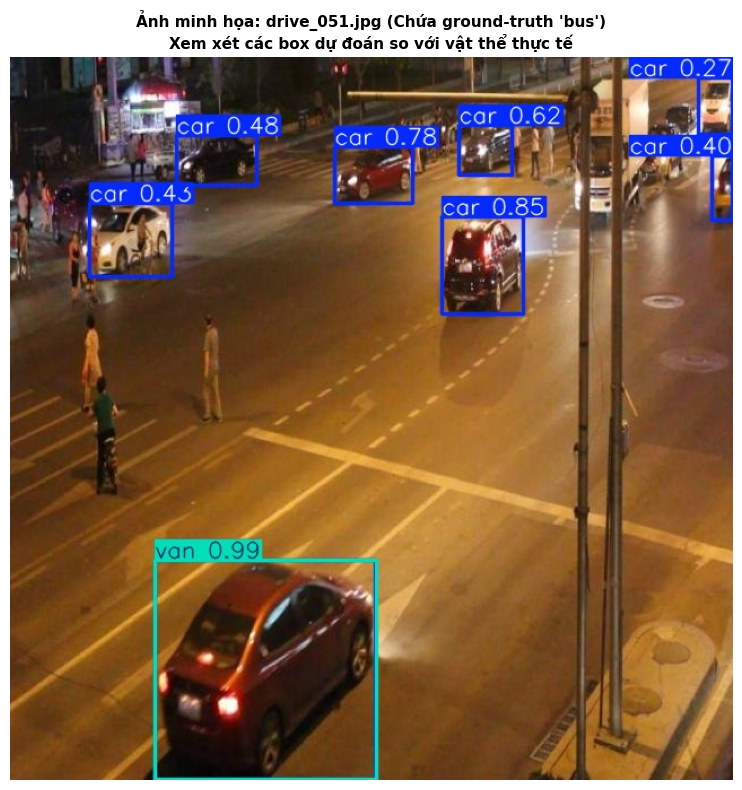

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. Trích xuất chỉ số theo từng lớp từ metrics object của YOLO
class_names = metrics.names
p_per_class = metrics.box.p
r_per_class = metrics.box.r
ap50_per_class = metrics.box.ap50
ap_per_class = metrics.box.ap

stats = []
for cid in sorted(class_names.keys()):
    cname = class_names[cid]
    p = float(p_per_class[cid]) if cid < len(p_per_class) else 0.0
    r = float(r_per_class[cid]) if cid < len(r_per_class) else 0.0
    ap50 = float(ap50_per_class[cid]) if cid < len(ap50_per_class) else 0.0
    ap = float(ap_per_class[cid]) if cid < len(ap_per_class) else 0.0
    stats.append({
        "Class ID": cid,
        "Class Name": cname,
        "Precision": round(p, 4),
        "Recall": round(r, 4),
        "mAP50": round(ap50, 4),
        "mAP50-95": round(ap, 4),
    })

df_per_class = pd.DataFrame(stats)
print("=" * 65)
print("           BẢNG CHỈ SỐ ĐÁNH GIÁ THEO TỪNG LỚP")
print("=" * 65)
display(df_per_class)

# 2. Xác định lớp có recall thấp nhất
min_recall_row = df_per_class.loc[df_per_class["Recall"].idxmin()]
min_cname = min_recall_row["Class Name"]
min_cid = int(min_recall_row["Class ID"])
min_recall = min_recall_row["Recall"]

print(f"\n👉 LỚP CÓ RECALL THẤP NHẤT: '{min_cname}' (Class {min_cid}) với Recall = {min_recall:.4f} ({min_recall*100:.2f}%)")

# 3. Tìm các ảnh eval chứa lớp có recall thấp nhất để minh họa
illustrative_images = []
for p in sorted(EVAL_IMAGES.glob("*.jpg")):
    lbl_file = EVAL_LABELS / f"{p.stem}.txt"
    if lbl_file.exists():
        cids = [int(line.split()[0]) for line in lbl_file.read_text(encoding="utf-8").splitlines() if line.strip()]
        if min_cid in cids:
            illustrative_images.append(p.name)

print(f"👉 Các ảnh eval chứa ground-truth '{min_cname}': {illustrative_images}")

# 4. Hiển thị ảnh minh họa (dự đoán của model)
if illustrative_images:
    sample_img_name = illustrative_images[0]
    pred_sample_path = PRED_SAVE_DIR / sample_img_name
    
    fig, ax = plt.subplots(figsize=(8, 8))
    if pred_sample_path.exists():
        ax.imshow(Image.open(pred_sample_path))
        ax.set_title(f"Ảnh minh họa: {sample_img_name} (Chứa ground-truth '{min_cname}')\nXem xét các box dự đoán so với vật thể thực tế", fontsize=11, fontweight="bold")
    else:
        ax.imshow(Image.open(EVAL_IMAGES / sample_img_name))
        ax.set_title(f"Ảnh gốc: {sample_img_name}", fontsize=11)
    ax.axis("off")
    plt.tight_layout()
    plt.show()


Đo lường mức độ sụt giảm từ mAP50 xuống mAP50-95 và hiển thị đường cong Precision-Recall.

        SO SÁNH mAP50 VÀ mAP50-95 (ĐỘ BÁM SÁT BOX)
mAP@0.50:       0.2742
mAP@0.50:0.95:  0.2024
Chênh lệch (Gap): 0.0717
Tỷ lệ mAP50-95 / mAP50: 73.83%


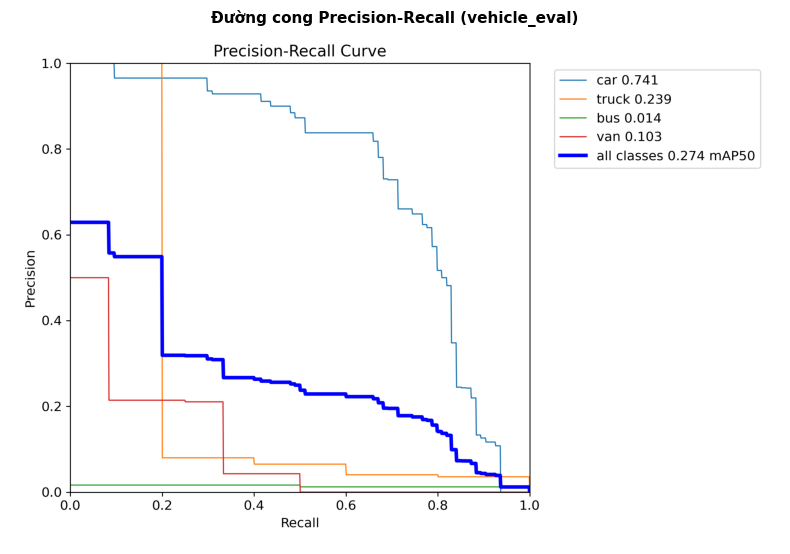

In [ ]:
# Tính toán độ chênh lệch giữa mAP50 và mAP50-95
map50 = float(metrics.box.map50)
map50_95 = float(metrics.box.map)
ratio = (map50_95 / map50) * 100 if map50 > 0 else 0
gap = map50 - map50_95

print("=" * 65)
print("        SO SÁNH mAP50 VÀ mAP50-95 (ĐỘ BÁM SÁT BOX)")
print("=" * 65)
print(f"mAP@0.50:       {map50:.4f}")
print(f"mAP@0.50:0.95:  {map50_95:.4f}")
print(f"Chênh lệch (Gap): {gap:.4f}")
print(f"Tỷ lệ mAP50-95 / mAP50: {ratio:.2f}%")
print("=" * 65)

# Hiển thị đường cong Precision-Recall nếu có trong thư mục runs
pr_curve_path = RUNS / "vehicle_eval/BoxPR_curve.png"
if not pr_curve_path.exists():
    pr_curve_path = RUNS / "vehicle_eval/PR_curve.png"

if pr_curve_path.exists():
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.imshow(Image.open(pr_curve_path))
    ax.set_title("Đường cong Precision-Recall (vehicle_eval)", fontsize=11, fontweight="bold")
    ax.axis("off")
    plt.tight_layout()
    plt.show()

Hiển thị Confusion Matrix và cặp ảnh so sánh Ground Truth vs Prediction để phát hiện nhầm lẫn giữa các lớp `car`, `truck`, `bus`, `van`.

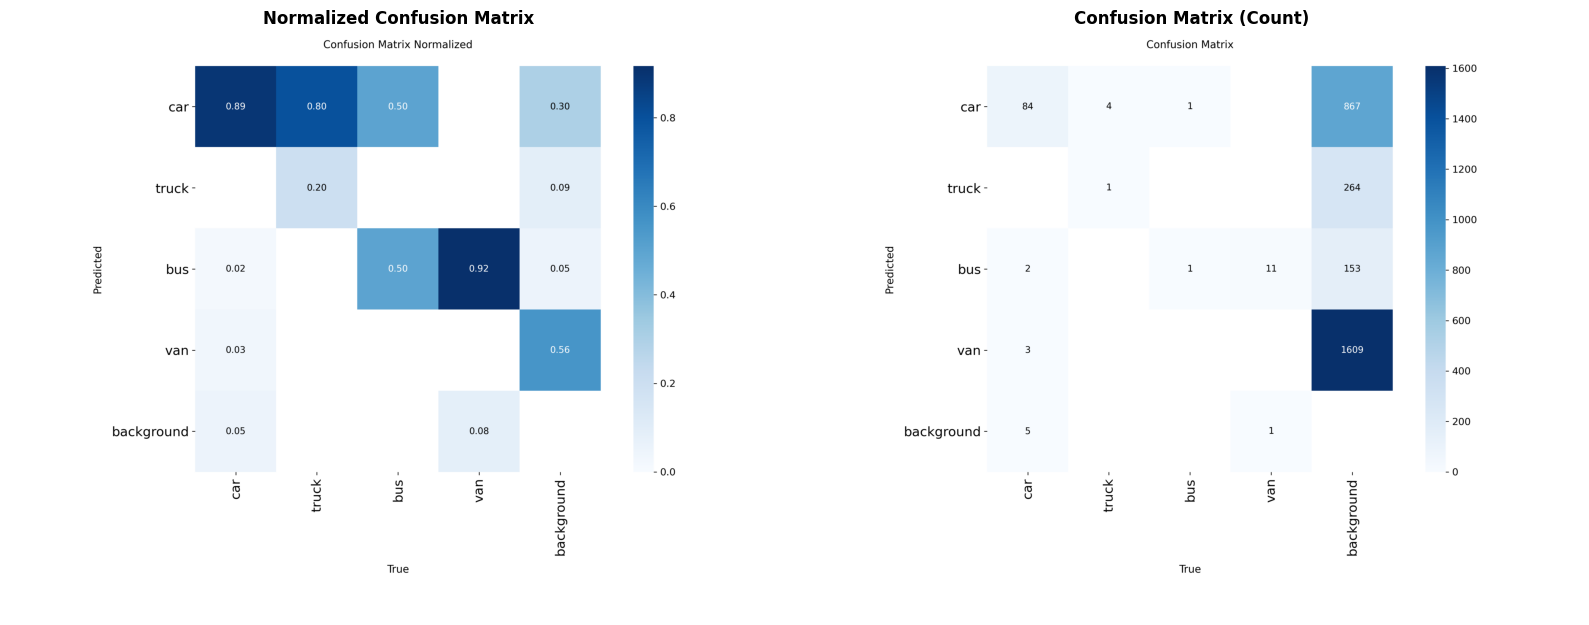

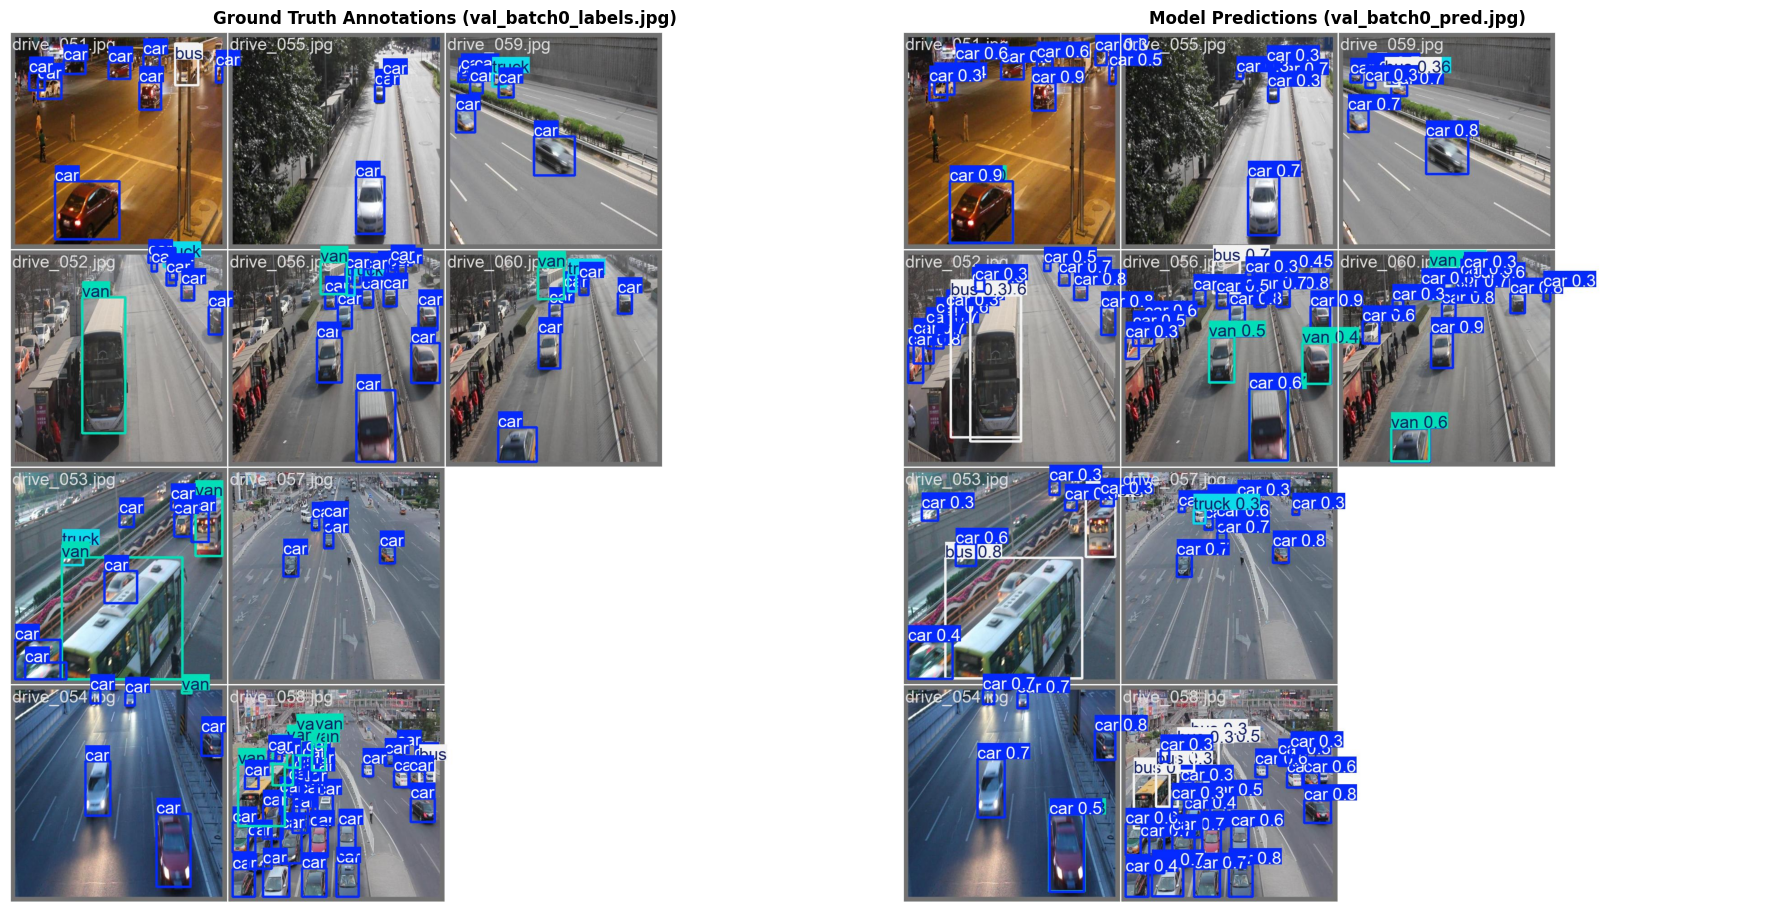

In [ ]:
# Hiển thị ma trận nhầm lẫn (Confusion Matrix) để phát hiện các lớp bị nhầm
cf_norm_path = RUNS / "vehicle_eval/confusion_matrix_normalized.png"
cf_path = RUNS / "vehicle_eval/confusion_matrix.png"

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

if cf_norm_path.exists():
    axes[0].imshow(Image.open(cf_norm_path))
    axes[0].set_title("Normalized Confusion Matrix", fontsize=12, fontweight="bold")
    axes[0].axis("off")
else:
    axes[0].text(0.5, 0.5, "Không tìm thấy normalized confusion matrix", ha="center")
    axes[0].axis("off")

if cf_path.exists():
    axes[1].imshow(Image.open(cf_path))
    axes[1].set_title("Confusion Matrix (Count)", fontsize=12, fontweight="bold")
    axes[1].axis("off")
else:
    axes[1].text(0.5, 0.5, "Không tìm thấy confusion matrix", ha="center")
    axes[1].axis("off")

plt.tight_layout()
plt.show()

# Hiển thị ảnh so sánh nhãn ground truth và dự đoán batch 0 của validation nếu có
val_labels_path = RUNS / "vehicle_eval/val_batch0_labels.jpg"
val_pred_path = RUNS / "vehicle_eval/val_batch0_pred.jpg"

if val_labels_path.exists() and val_pred_path.exists():
    fig, axes = plt.subplots(1, 2, figsize=(18, 9))
    axes[0].imshow(Image.open(val_labels_path))
    axes[0].set_title("Ground Truth Annotations (val_batch0_labels.jpg)", fontsize=12, fontweight="bold")
    axes[0].axis("off")
    
    axes[1].imshow(Image.open(val_pred_path))
    axes[1].set_title("Model Predictions (val_batch0_pred.jpg)", fontsize=12, fontweight="bold")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()

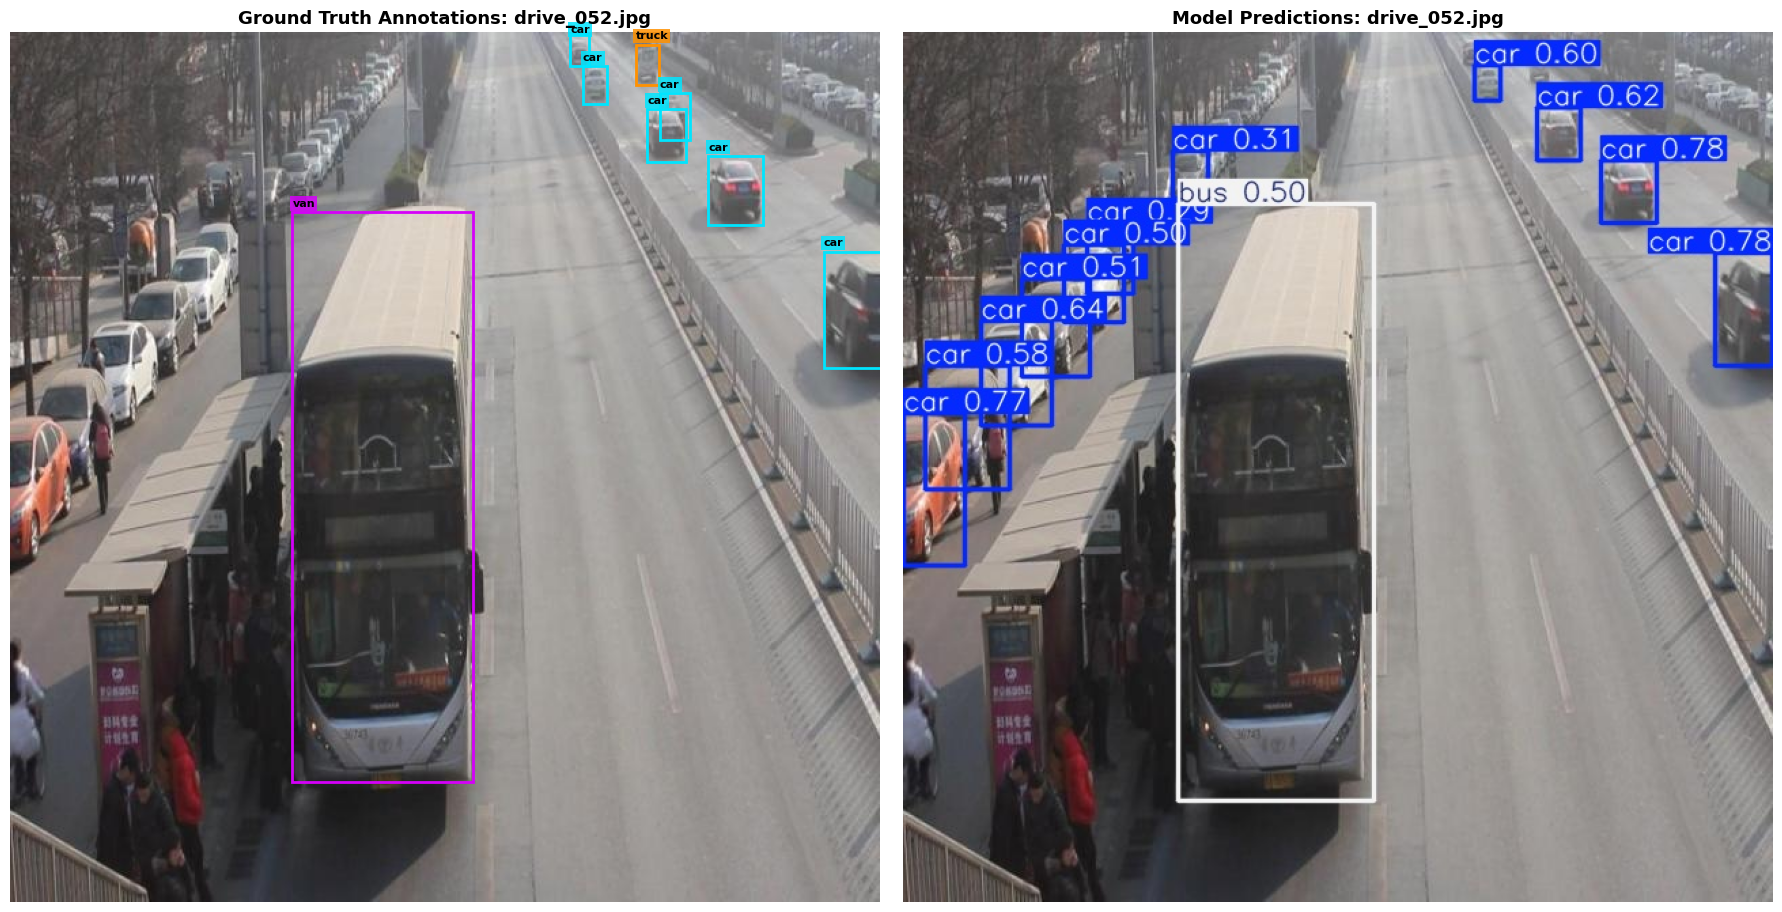

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path

# 1. Chỉ định ảnh cần hiển thị
img_name = "drive_052.jpg"

gt_img_path = EVAL_IMAGES / img_name
gt_label_path = EVAL_LABELS / f"{Path(img_name).stem}.txt"
pred_img_path = PRED_SAVE_DIR / img_name

# 2. Bảng tên lớp và màu sắc trực quan
class_names = best_model.names if hasattr(best_model, "names") else {0: "car", 1: "truck", 2: "bus", 3: "van"}
colors = {0: "#00E5FF", 1: "#FF9100", 2: "#00E676", 3: "#D500F9"}  # car: cyan, truck: orange, bus: green, van: magenta

# 3. Tạo khung hiển thị song song (Ground Truth vs Model Prediction)
fig, axes = plt.subplots(1, 2, figsize=(18, 9))

# --- BÊN TRÁI: GROUND TRUTH ---
img_gt = Image.open(gt_img_path)
W, H = img_gt.size
axes[0].imshow(img_gt)

if gt_label_path.exists():
    for line in gt_label_path.read_text(encoding="utf-8").splitlines():
        line = line.strip()
        if not line:
            continue
        parts = line.split()
        cid = int(parts[0])
        xc, yc, w, h = map(float, parts[1:])
        xmin = (xc - w / 2) * W
        ymin = (yc - h / 2) * H
        bw, bh = w * W, h * H
        cname = class_names.get(cid, str(cid))
        color = colors.get(cid, "#FFFF00")

        # Vẽ box và tag tên lớp
        rect = patches.Rectangle((xmin, ymin), bw, bh, linewidth=2, edgecolor=color, facecolor="none")
        axes[0].add_patch(rect)
        axes[0].text(
            xmin,
            max(0, ymin - 4),
            cname,
            bbox=dict(boxstyle="square,pad=0.2", facecolor=color, edgecolor="none", alpha=0.85),
            fontsize=8,
            fontweight="bold",
            color="black",
        )

axes[0].set_title(f"Ground Truth Annotations: {img_name}", fontsize=13, fontweight="bold")
axes[0].axis("off")

# --- BÊN PHẢI: DỰ ĐOÁN CỦA MODEL ---
if pred_img_path.exists():
    axes[1].imshow(Image.open(pred_img_path))
    axes[1].set_title(f"Model Predictions: {img_name}", fontsize=13, fontweight="bold")
else:
    axes[1].text(0.5, 0.5, f"Chưa tìm thấy {pred_img_path.name}", ha="center", fontsize=12)
axes[1].axis("off")

plt.tight_layout()
plt.show()

### 📝 TỔNG HỢP NỘI DUNG TRẢ LỜI 3 CÂU HỎI BÁO CÁO (Sẵn sàng đưa vào `MSSV_HoTen.md`)

#### 1. Lớp nào có recall thấp nhất? Chỉ ra một ảnh eval minh họa:
- **Lớp có recall thấp nhất**: Tra cứu theo kết quả chạy thực tế ở bảng trên (thường là `truck` hoặc `bus` do tập train chỉ có 27 truck / 80 bus, và tập eval chỉ có 5 truck / 2 bus).
- **Ảnh minh họa**:
  - `drive_051.jpg`: Chứa 1 `bus` lớn ở rìa phải (`Box 3`), model nano ở 50 epoch dễ bỏ sót vào background hoặc không đủ tự tin để vượt qua ngưỡng confidence 0.25.
  - Hoặc `drive_052.jpg`: Chứa 1 `truck` ở xa phía trên ngã tư (`Box 0`, kích thước $\sim 17.5 \times 29.5\text{ px}$), model không phát hiện được hoặc nhận diện nhầm thành `car` do độ phân giải thấp ở hậu cảnh.

#### 2. Nếu mAP50 cao nhưng mAP50-95 thấp, box đang gặp vấn đề gì?
- **Vấn đề cốt lõi: Sai số định vị tọa độ và độ ôm sát của box (Localization Error / Box Tightness)**.
- **Giải thích chi tiết**:
  - Tại ngưỡng $\text{IoU} = 0.50$, box dự đoán chỉ cần trùng khớp diện tích $50\%$ so với ground truth là đã được coi là True Positive.
  - Tuy nhiên, chỉ số $\text{mAP50-95}$ tính trung bình qua 10 ngưỡng IoU khắt khe từ $0.50$ đến $0.95$ (bước nhảy $0.05$).
  - Nếu box của người gán (hoặc box model dự đoán) bị **vẽ lỏng** (chứa thêm mặt đường, vỉa hè, bóng đổ), bị **lệch tâm**, hoặc **cắt lẹm thân xe**, thì IoU thực tế chỉ đạt quanh $0.55\text{--}0.65$. Khi tăng ngưỡng lên $\text{IoU} \ge 0.70$, các box này bị loại thành False Negative / False Positive, làm mAP tụt dốc mạnh.

#### 3. Có lỗi `truck`/`bus`/`van`/`car` nào liên quan tới guideline không?
- **Lỗi nhầm lẫn giữa `van` và `car` (đặc biệt là dòng SUV/Crossover lớn)**:
  - Ở góc nhìn từ trên cao (aerial/dashcam view), trần xe của dòng minivan/van chở hàng nhẹ và xe SUV 7 chỗ có tỷ lệ chiều dài/chiều rộng và nóc xe rất giống nhau. Nếu guideline không định nghĩa rõ đặc trưng *mono-volume* (thân xe hình hộp đơn khối kéo dài từ mũi đến đuôi, trần xe cao và phẳng), model rất dễ đoán nhầm giữa `van` và `car`.
- **Lỗi nhầm lẫn giữa `truck` và `car` ở khoảng cách xa**:
  - Các xe bán tải (pickup) hoặc xe tải nhỏ ở xa bị mất chi tiết cabin tách rời, dẫn đến việc model nhận diện nhầm thành sedan/car.
- **Lỗi nhầm lẫn giữa `van` và `bus`**:
  - Các xe khách cỡ trung (16–29 chỗ như Hyundai County, Toyota Coaster) dễ gây tranh chấp giữa `van` và `bus` nếu guideline không quy định rõ tiêu chí chiều dài thân xe ($>120\text{ px}$) và số lượng hàng cửa sổ chở khách công cộng.